<a href="https://colab.research.google.com/github/hilduAgl/brain-age-eeg/blob/eda/notebooks/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis

This notebook explores the preprocessed EEG dataset used for brain age prediction.

## Goals

- Load and inspect the EEG data
- Examine the train/validation/test splits
- Explore the age distribution
- Inspect EEG dimensions and channels
- Visualize example EEG recordings
- Compute basic dataset statistics

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Dataset setup

The dataset contains preprocessed EEG recordings together with age and sex metadata. We first inspect the available subjects, metadata, EEG dimensions, and the provided train/validation/test split.

In [2]:
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "/content/drive/MyDrive/BrainAge/data"
EEG_DIR = os.path.join(DATA_DIR, "pre_processed")
METADATA_PATH = os.path.join(DATA_DIR, "anon_codex_age_sex.csv")

In [3]:
metadata = pd.read_csv(METADATA_PATH)

print("Metadata shape:", metadata.shape)
display(metadata.head())

print(metadata.columns.tolist())
print()
metadata.info()

eeg_files = sorted([
    f for f in os.listdir(EEG_DIR)
    if f.endswith(".pt")
])

print("Number of preprocessed EEG files:", len(eeg_files))
print("First 10 files:")
print(eeg_files[:10])

example_path = os.path.join(EEG_DIR, eeg_files[0])

eeg = torch.load(example_path)

print("File:", eeg_files[0])
print("Type:", type(eeg))
print("Shape:", eeg.shape)
print("Data type:", eeg.dtype)

Metadata shape: (1032, 3)


,Anon. Filename,Quantized Age (years),Quantized Sex
0,2Y32V8.edf,1.487123,Female
1,73K37E.edf,0.375068,Male
2,3FU420.edf,1.841644,Male
3,D9017K.edf,8.061644,Female
4,2QC868.edf,8.880946,Female


['Anon. Filename', 'Quantized Age (years)', 'Quantized Sex']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1032 entries, 0 to 1031
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Anon. Filename         1032 non-null   object 
 1   Quantized Age (years)  1032 non-null   float64
 2   Quantized Sex          1032 non-null   object 
dtypes: float64(1), object(2)
memory usage: 24.3+ KB
Number of preprocessed EEG files: 1034
First 10 files:
['003FL6.pt', '00B64O.pt', '0151RC.pt', '015W5S.pt', '016EF1.pt', '02X87C.pt', '03E99T.pt', '03Q8Y5.pt', '03Z15R.pt', '043I5D.pt']
File: 003FL6.pt
Type: <class 'torch.Tensor'>
Shape: torch.Size([20, 57664])
Data type: torch.float16


## 2. Metadata exploration

We examine the distribution of chronological age and sex in the dataset and check for missing or unusual values.

Number of subjects: 1032
Minimum age: 0.16 years
Maximum age: 16.01 years
Mean age: 4.50 years
Median age: 2.81 years

Sex counts:
Quantized Sex
Male      533
Female    499
Name: count, dtype: int64

Missing values:
Anon. Filename           0
Quantized Age (years)    0
Quantized Sex            0
dtype: int64


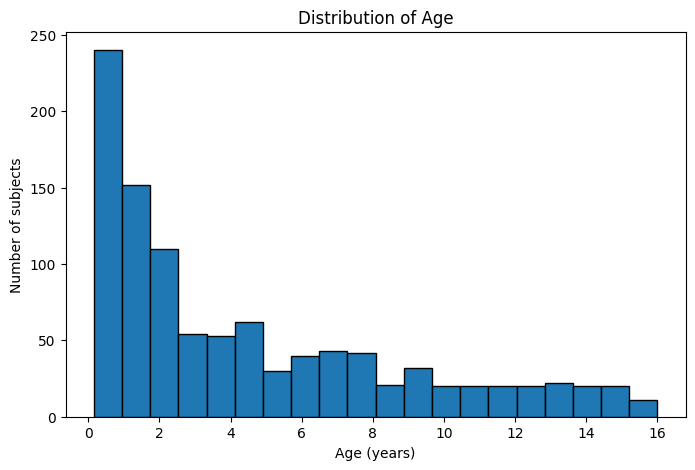

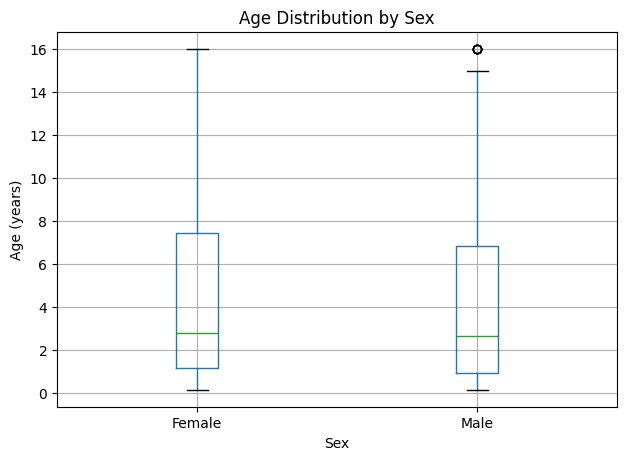

Subjects in metadata: 1032
EEG files: 1034

EEG files without metadata:
['177T6O (1)', '48M4B1 (1)']

Metadata entries without EEG:
[]


In [4]:
AGE_COL = "Quantized Age (years)"
SEX_COL = "Quantized Sex"
FILE_COL = "Anon. Filename"

metadata.describe(include="all")

print(f"Number of subjects: {len(metadata)}")
print(f"Minimum age: {metadata[AGE_COL].min():.2f} years")
print(f"Maximum age: {metadata[AGE_COL].max():.2f} years")
print(f"Mean age: {metadata[AGE_COL].mean():.2f} years")
print(f"Median age: {metadata[AGE_COL].median():.2f} years")

print("\nSex counts:")
print(metadata[SEX_COL].value_counts())

print("\nMissing values:")
print(metadata.isnull().sum())

plt.figure(figsize=(8, 5))
plt.hist(metadata[AGE_COL], bins=20, edgecolor="black")

plt.xlabel("Age (years)")
plt.ylabel("Number of subjects")
plt.title("Distribution of Age")

plt.show()

metadata[SEX_COL].value_counts()

metadata.boxplot(
    column=AGE_COL,
    by=SEX_COL,
    figsize=(7, 5)
)

plt.title("Age Distribution by Sex")
plt.suptitle("")
plt.xlabel("Sex")
plt.ylabel("Age (years)")
plt.show()

metadata_ids = set(
    metadata[FILE_COL]
    .str.replace(".edf", "", regex=False)
)

eeg_ids = set(
    f.replace(".pt", "")
    for f in eeg_files
)

print("Subjects in metadata:", len(metadata_ids))
print("EEG files:", len(eeg_ids))

print("\nEEG files without metadata:")
print(sorted(eeg_ids - metadata_ids))

print("\nMetadata entries without EEG:")
print(sorted(metadata_ids - eeg_ids))

In [5]:
from collections import Counter

shapes = []

for filename in eeg_files:
    eeg_temp = torch.load(os.path.join(EEG_DIR, filename))
    shapes.append(tuple(eeg_temp.shape))

shape_counts = Counter(shapes)

print("Number of unique shapes:", len(shape_counts))

for shape, count in shape_counts.most_common():
    print(shape, ":", count)

Number of unique shapes: 2
(20, 57664) : 1033
(20, 60672) : 1


## 3. Train, validation, and test splits

We inspect the provided train, validation, and test splits to determine their structure, number of subjects, age distributions, and whether any subjects occur in more than one split.

In [6]:
TRAIN_PATH = os.path.join(DATA_DIR, "segments_h1k_train.pt")
VAL_PATH = os.path.join(DATA_DIR, "segments_h1k_val.pt")
TEST_PATH = os.path.join(DATA_DIR, "segments_h1k_test.pt")

train_data = torch.load(TRAIN_PATH)
val_data = torch.load(VAL_PATH)
test_data = torch.load(TEST_PATH)

print("Train type:", type(train_data))
print("Validation type:", type(val_data))
print("Test type:", type(test_data))

print("Train length:", len(train_data))
print("Validation length:", len(val_data))
print("Test length:", len(test_data))

print("\nFirst training entry:")
print(train_data[0])
print("\nEntry type:", type(train_data[0]))

Train type: <class 'list'>
Validation type: <class 'list'>
Test type: <class 'list'>
Train length: 825
Validation length: 103
Test length: 104

First training entry:
(0, 901, 0, 5.284383562, '8128DH.edf')

Entry type: <class 'tuple'>


In [7]:
# Extract subject filenames from each split
train_subjects = {entry[4] for entry in train_data}
val_subjects = {entry[4] for entry in val_data}
test_subjects = {entry[4] for entry in test_data}

print("Unique train subjects:", len(train_subjects))
print("Unique validation subjects:", len(val_subjects))
print("Unique test subjects:", len(test_subjects))

print("\nSubject overlap:")
print("Train ∩ Validation:", len(train_subjects & val_subjects))
print("Train ∩ Test:", len(train_subjects & test_subjects))
print("Validation ∩ Test:", len(val_subjects & test_subjects))

total = len(train_data) + len(val_data) + len(test_data)

print(f"Train:      {len(train_data)} ({len(train_data)/total:.1%})")
print(f"Validation: {len(val_data)} ({len(val_data)/total:.1%})")
print(f"Test:       {len(test_data)} ({len(test_data)/total:.1%})")

Unique train subjects: 825
Unique validation subjects: 103
Unique test subjects: 104

Subject overlap:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0
Train:      825 (79.9%)
Validation: 103 (10.0%)
Test:       104 (10.1%)


Train:
  Mean age: 4.59
  Min age:  0.16
  Max age:  16.01

Validation:
  Mean age: 3.78
  Min age:  0.16
  Max age:  16.01

Test:
  Mean age: 4.48
  Min age:  0.16
  Max age:  16.01


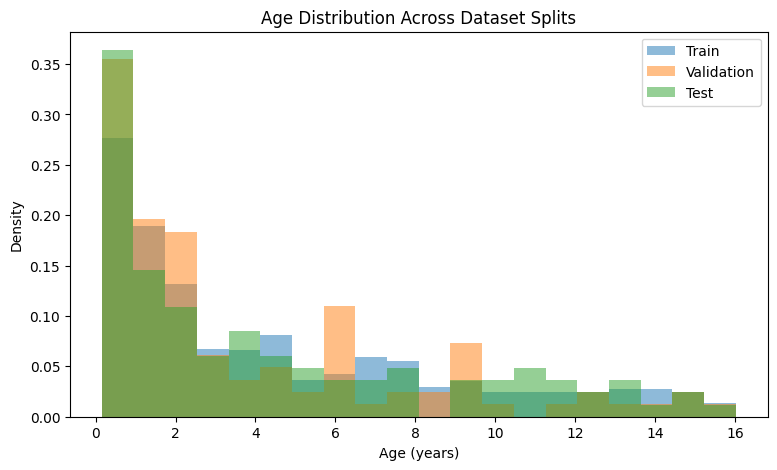

In [8]:
train_ages = np.array([entry[3] for entry in train_data])
val_ages = np.array([entry[3] for entry in val_data])
test_ages = np.array([entry[3] for entry in test_data])

print("Train:")
print(f"  Mean age: {train_ages.mean():.2f}")
print(f"  Min age:  {train_ages.min():.2f}")
print(f"  Max age:  {train_ages.max():.2f}")

print("\nValidation:")
print(f"  Mean age: {val_ages.mean():.2f}")
print(f"  Min age:  {val_ages.min():.2f}")
print(f"  Max age:  {val_ages.max():.2f}")

print("\nTest:")
print(f"  Mean age: {test_ages.mean():.2f}")
print(f"  Min age:  {test_ages.min():.2f}")
print(f"  Max age:  {test_ages.max():.2f}")

plt.figure(figsize=(9, 5))

plt.hist(train_ages, bins=20, alpha=0.5, label="Train", density=True)
plt.hist(val_ages, bins=20, alpha=0.5, label="Validation", density=True)
plt.hist(test_ages, bins=20, alpha=0.5, label="Test", density=True)

plt.xlabel("Age (years)")
plt.ylabel("Density")
plt.title("Age Distribution Across Dataset Splits")
plt.legend()

plt.show()

### Split observations

- The dataset is divided approximately 80% / 10% / 10% into training, validation, and test sets.
- Each subject occurs in exactly one split; no subject overlap was found between training, validation, and test sets.
- All three splits cover the full age range of approximately 0.16–16.01 years.
- The age distribution is strongly skewed toward younger children.
- The validation set has a somewhat lower mean age (3.78 years) than the training (4.59 years) and test (4.48 years) sets.

## 4. EEG signal visualization

The preprocessed recordings contain 20 bipolar EEG channels. Each channel represents the voltage difference between a pair of scalp electrodes. The recordings have been filtered and resampled to 64 Hz.

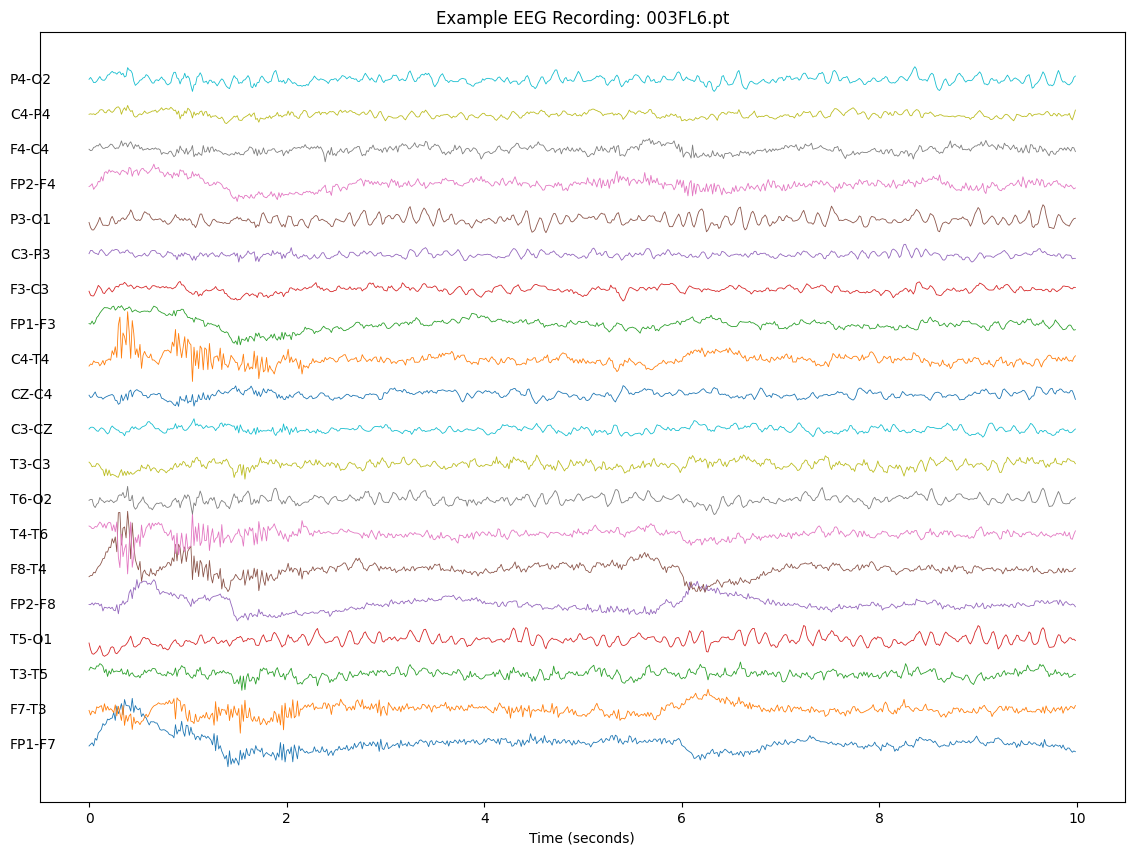

In [11]:
montage = [
    'FP1-F7', 'F7-T3', 'T3-T5', 'T5-O1',
    'FP2-F8', 'F8-T4', 'T4-T6', 'T6-O2',
    'T3-C3', 'C3-CZ', 'CZ-C4', 'C4-T4',
    'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1',
    'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2'
]

RESAMPLING_RATE = 64

# Choose an example recording
example_file = eeg_files[0]
example_eeg = torch.load(os.path.join(EEG_DIR, example_file))

# Display the first 10 seconds
start_seconds = 0
duration_seconds = 10

start = start_seconds * RESAMPLING_RATE
end = (start_seconds + duration_seconds) * RESAMPLING_RATE

time = np.arange(start, end) / RESAMPLING_RATE

plt.figure(figsize=(14, 10))

offset = 0
spacing = 150

for channel in range(example_eeg.shape[0]):
    signal = example_eeg[channel, start:end]

    plt.plot(time, signal + offset, linewidth=0.6)
    plt.text(
        time[0] - 0.8,
        offset,
        montage[channel],
        verticalalignment="center"
    )

    offset += spacing

plt.xlabel("Time (seconds)")
plt.title(f"Example EEG Recording: {example_file}")
plt.yticks([])
plt.show()

### Observation

The figure shows the first 10 seconds of one preprocessed EEG recording across all 20 bipolar channels. Each channel represents the voltage difference between a pair of electrodes. The channels show visibly different signal patterns and amplitudes, and some contain relatively large fluctuations. This illustrates the multi-channel structure of the EEG data and the potential presence of artifacts or noise.

## 5. Channel quality analysis

To select a channel for the simple feature-based baseline, we compare signal characteristics across the 20 bipolar EEG channels using training data only. The goal is to identify a channel that is relatively stable across subjects and does not frequently contain extreme amplitudes.

In [12]:
channel_stds = []
channel_max_abs = []

for filename in train_subjects:
    pt_filename = filename.replace(".edf", ".pt")
    path = os.path.join(EEG_DIR, pt_filename)

    eeg = torch.load(path).float()

    channel_stds.append(
        eeg.std(dim=1).numpy()
    )

    channel_max_abs.append(
        eeg.abs().max(dim=1).values.numpy()
    )

channel_stds = np.array(channel_stds)
channel_max_abs = np.array(channel_max_abs)

print(channel_stds.shape)

(825, 20)


In [13]:
channel_summary = pd.DataFrame({
    "Channel": montage,
    "Median SD": np.median(channel_stds, axis=0),
    "Mean SD": np.mean(channel_stds, axis=0),
    "95th percentile SD": np.percentile(channel_stds, 95, axis=0),
    "Median max amplitude": np.median(channel_max_abs, axis=0)
})

channel_summary.sort_values("Median SD")

,Channel,Median SD,Mean SD,95th percentile SD,Median max amplitude
0,FP1-F7,24.778166,32.701618,83.977959,262.500
4,FP2-F8,24.786465,34.212341,86.653229,253.750
1,F7-T3,25.983826,30.201969,70.951515,216.000
5,F8-T4,26.060028,31.893757,80.399475,224.500
14,C3-P3,26.338736,29.865822,59.336704,227.250
2,T3-T5,26.471769,30.845495,69.893448,235.500
18,C4-P4,26.898085,31.488127,70.305107,227.875
9,C3-CZ,27.798218,29.730684,55.463680,250.875
12,FP1-F3,27.906101,34.611431,83.764107,284.750
13,F3-C3,28.125185,30.729847,57.592743,248.625


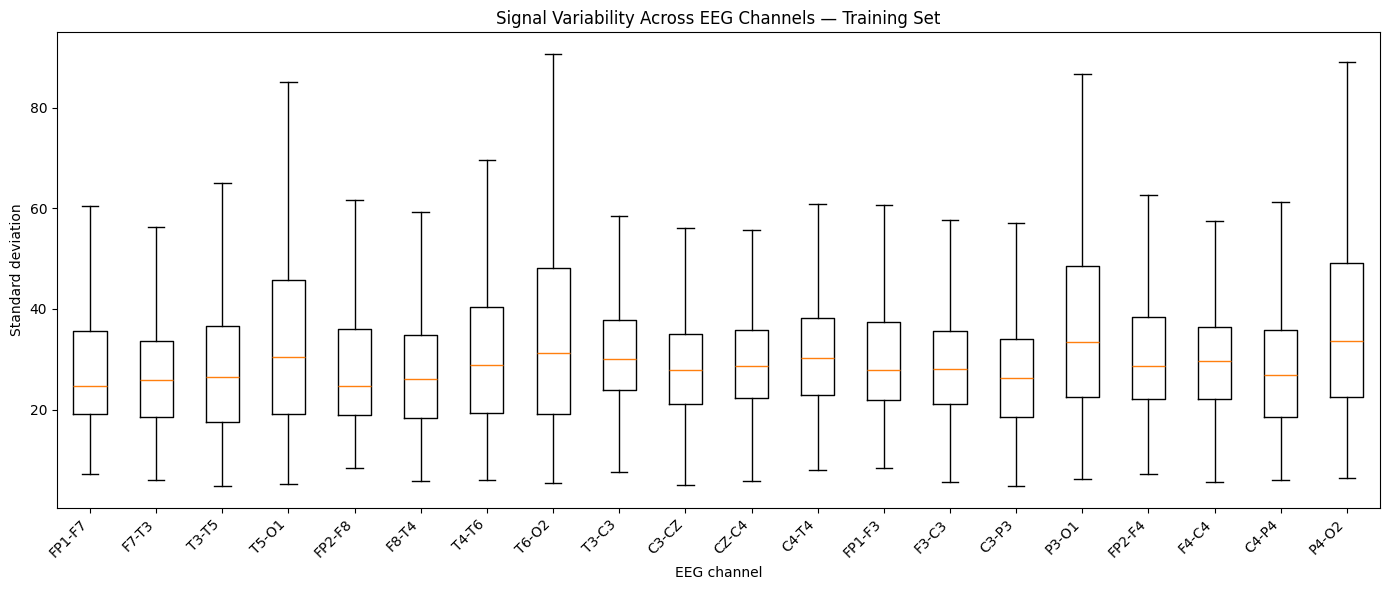

In [14]:
plt.figure(figsize=(14, 6))

plt.boxplot(
    [channel_stds[:, i] for i in range(20)],
    tick_labels=montage,
    showfliers=False
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("EEG channel")
plt.ylabel("Standard deviation")
plt.title("Signal Variability Across EEG Channels — Training Set")

plt.tight_layout()
plt.show()

### Channel selection for the baseline

For the initial single-channel feature-based baseline, we selected **C3-P3 (channel 14)**.

Channel variability was compared across the training set using the standard deviation and maximum absolute amplitude of each recording. C3-P3 had relatively low typical variability (median SD = 26.34), low mean variability (29.87), and a comparatively low 95th-percentile SD (59.34).

Although some frontal channels had slightly lower median standard deviations, their upper-end variability was substantially higher. C3-P3 therefore provides a reasonable relatively stable channel for the initial baseline.

This selection is intended as a simple starting point rather than a claim that C3-P3 is the optimal channel for age prediction.